# Lab 6
- **Student Name**: Daniel Alejandro Castillo Martin
- **Student ID**: N10019284
- **Course:** Advanced Deep Learning - AIGC-5500-0NA
- **Professor**: Hossein Pourmodheji
---

## Overview

This lab investigates parameter-efficient fine-tuning (PEFT) by adapting the pretrained **HuggingFaceTB/SmolLM2-135M** language model to a text classification task using Low-Rank Adaptation (LoRA).

The experiments compare full fine-tuning against LoRA at different ranks, evaluating classification accuracy, trainable parameter counts, computational cost, and memory consumption.

## Objectives

1. Evaluate the pre-trained model using a zero-shot classification baseline.
2. Implement answer-only loss masking to focus training on classification labels.
3. Implement LoRA from scratch and validate its behavior against the PEFT library.
4. Compare full fine-tuning with LoRA ranks 1, 4, and 16 using controlled experiments.
5. Predict and measure memory consumption across fine-tuning configurations.
6. Analyze the trade-offs between accuracy, parameter efficiency, and computational resources.


## 1. Imports and Setup




- This section initializes the libraries, configuration parameters, and execution environment required for the experiments.

- The implementation uses PyTorch for tensor operations and model training, Hugging Face Transformers for pretrained language models, and PEFT for validating the custom LoRA implementation.

- The provided `lab06_starter.py` module supplies standardized dataset loading, training, evaluation, and memory-measurement utilities, ensuring consistent experimental conditions.

### 1.1 Required Libraries

In [31]:
# Import general libraries for reproducibility and paths
import sys
import subprocess

# Import libraries for data analysis and visualization
import matplotlib.pyplot as plt
import pandas as pd

# Import libraries for model operations and verification
import torch
import torch.nn as nn
import torch.nn.functional as F
from peft import LoraConfig, get_peft_model

# Import the provided lab starter
from scripts import lab06_starter as S

# Import project custom modules
from src.config import (MODEL_NAME, TASK_NAME, SEEDS, DATA_SEED, N_TRAIN, N_TEST, LORA_RANKS, TRAINING_STEPS, BATCH_SIZE, FULL_LR, LORA_LR, OUTPUT_DIR, FIGURES_DIR, create_output_directories)
from src.utils import set_seed, get_hardware_info
from src.losses import answer_only_labels
from src.lora import LoRALinear
from src.verification import ReferenceModel, expected_lora_params
from src.experiments import run_experiment, run_sweep
from src.memory import predict_training_memory

# Ignore warnings
import warnings
warnings.filterwarnings('ignore')

### 1.2 Experiment Configuration


- The experiment settings are defined centrally to ensure consistency and reproducibility across fine-tuning methods.

- All configurations will use the same dataset, evaluation split, training steps, batch size, and random seeds. Learning rates may differ between full fine-tuning and LoRA, as permitted by the assignment.

- Generated results and figures will be stored separately from the source code.

In [2]:
# Initialize the experiment output directories
create_output_directories()

# Display the experimental configuration
print(f'Model: {MODEL_NAME}')
print(f'Task: {TASK_NAME}')
print(f'Training examples: {N_TRAIN}')
print(f'Test examples: {N_TEST}')
print(f'Data seed: {DATA_SEED}')
print(f'Training seeds: {SEEDS}')
print(f'LoRA ranks: {LORA_RANKS}')
print(f'Training steps: {TRAINING_STEPS}')
print(f'Batch size: {BATCH_SIZE}')
print(f'Full fine-tuning LR: {FULL_LR}')
print(f'LoRA LR: {LORA_LR}')

Model: HuggingFaceTB/SmolLM2-135M
Task: emotion
Training examples: 600
Test examples: 500
Data seed: 0
Training seeds: [0, 1, 2]
LoRA ranks: [1, 4, 16]
Training steps: 120
Batch size: 8
Full fine-tuning LR: 5e-05
LoRA LR: 0.001


### 1.3 Reproducibility and Hardware

- Reproducibility is important for ensuring that observed differences between full fine-tuning and LoRA configurations are attributable to the methods being compared rather than uncontrolled randomness.

- The experiments use fixed random seeds for Python and PyTorch, consistent dataset sampling, and identical training budgets across configurations. Each experiment will be repeated using seeds 0, 1, and 2.

- The available hardware and software environment are also recorded because training time and GPU memory consumption depend on the execution platform.

In [3]:
# Initialize reproducibility with the first experimental seed
set_seed(SEEDS[0])

# Retrieve and display the execution environment
hardware_info = get_hardware_info()

for key, value in hardware_info.items():
    print(f'{key}: {value}')

Python: 3.12.10
PyTorch: 2.8.0+cu128
CUDA available: True
CUDA version: 12.8
Device: cuda
GPU: NVIDIA GeForce RTX 3060 Laptop GPU


### 1.4 Starter Script Validation

- Before implementing the custom LoRA components, the provided `lab06_starter.py` script is executed without modification to validate the experimental environment.

- The starter loads the pretrained SmolLM2-135M model and the emotion classification dataset, evaluates zero-shot accuracy, and performs a short 30-step LoRA training run using PEFT.

- This preliminary test verifies that model loading, dataset preparation, evaluation, and GPU-accelerated training work correctly before conducting the controlled experiments.

In [4]:
# Configure execution to test that the starter script works
result = subprocess.run([sys.executable, 'scripts/lab06_starter.py'], capture_output = True, text = True, encoding = 'utf-8',errors = 'replace')

# Display the execution output
print(result.stdout)

# Validate successful execution
assert result.returncode == 0, 'Starter script execution failed.'
print('Starter script validation completed successfully.')

device: cuda
example prompt: 'Text: i may feel that way but the fact that stories created by adults that are meant for children contain messages that are not so innocent really makes me wonder who exactly is\nEmotion:' answer: ' joy'
zero-shot accuracy (chance 0.167): 0.35
LoRA r=8, 30 steps: accuracy 0.510, trainable 460,800 of 134,975,808, 0.13 s/step

Starter script validation completed successfully.


#### Validation Results

The original starter script completed successfully using CUDA acceleration on the NVIDIA GeForce RTX 3060 Laptop GPU.

- **Zero-shot accuracy:** 35.0%, exceeding the random-chance baseline of 16.7%.
- **LoRA accuracy:** 51.0% after 30 training steps, representing a 16-percentage-point improvement.
- **Trainable parameters:** 460,800 out of 134,975,808 total parameters (approximately 0.34%).
- **Training time:** Approximately 0.12 seconds per step.

The results confirm that pretrained model loading, dataset preparation, evaluation, and LoRA fine-tuning are operational.

Although the preliminary LoRA run improved classification accuracy, this result alone does not establish whether LoRA matches full fine-tuning or how adaptation rank affects performance. Those comparisons require controlled experiments using identical datasets, training budgets, and random seeds.

## 2. Zero-Shot Baseline and Answer-Only Loss

- This section evaluates the pretrained language model before fine-tuning and introduces a task-specific loss function for emotion classification.

- The model performs classification without an additional classification head. Instead, each input is formatted as a text prompt ending with an emotion cue, and the model predicts the most likely label token.

- The zero-shot baseline provides a reference for measuring the effectiveness of subsequent fine-tuning experiments.

### 2.1 Model and Dataset Preparation

- The experiment uses **HuggingFaceTB/SmolLM2-135M**, a pretrained decoder-only language model, and the **dair-ai/emotion** dataset.

- The task includes six emotion categories: sadness, joy, love, anger, fear, and surprise.

- For controlled evaluation, 600 training examples and 500 test examples are selected using a fixed data seed. The same examples will be reused across all fine-tuning configurations.

In [5]:
# Load the pretrained language model and tokenizer
model, tokenizer = S.load_model()

# Load the emotion classification dataset using a fixed sampling seed
train_examples, test_examples, label_ids = S.load_task(
    task = TASK_NAME,
    n_train = N_TRAIN,
    n_test = N_TEST,
    data_seed = DATA_SEED,
    tokenizer = tokenizer
)

# Display the dataset and classification configuration
print(f'\nModel: {MODEL_NAME}')
print(f'Device: {S.DEVICE}')
print(f'Training examples: {len(train_examples)}')
print(f'Test examples: {len(test_examples)}')
print(f'Emotion classes: {S.TASKS[TASK_NAME]['words']}')


Loading weights: 100%|██████████| 272/272 [00:00<00:00, 1258.87it/s]



Model: HuggingFaceTB/SmolLM2-135M
Device: cuda
Training examples: 600
Test examples: 500
Emotion classes: ['sadness', 'joy', 'love', 'anger', 'fear', 'surprise']


In [6]:
# Inspect the first tokenized classification example
example = train_examples[0]

print('\nExample prompt:')
print(tokenizer.decode(example['prompt_ids']))

print('\nExpected label:')
print(S.TASKS[TASK_NAME]['words'][example['label']])

print('\nAnswer token:')
print(repr(tokenizer.decode([example['answer_id']])))


Example prompt:
Text: i may feel that way but the fact that stories created by adults that are meant for children contain messages that are not so innocent really makes me wonder who exactly is
Emotion:

Expected label:
joy

Answer token:
' joy'


### 2.2 Zero-Shot Baseline Evaluation


- Zero-shot evaluation measures the pretrained model's ability to perform emotion classification without task-specific fine-tuning.

- The model receives a text prompt ending with `Emotion:` and predicts the most likely emotion by comparing the logits associated with the six predefined label tokens.

- Since the task contains six classes, the uniform random-chance baseline is approximately 16.67%. The zero-shot accuracy provides a reference for measuring the improvements or regressions produced by subsequent fine-tuning experiments.

In [7]:
# Evaluate the pretrained model without fine-tuning
zero_shot_accuracy = S.evaluate(
    model = model,
    tok = tokenizer,
    test = test_examples,
    label_ids = label_ids,
    batch_size = 32
    )

# Calculate the uniform random-chance baseline
chance_accuracy = 1 / len(label_ids)

# Measure the difference between zero-shot accuracy and chance
baseline_improvement = zero_shot_accuracy - chance_accuracy

# Display baseline evaluation results
print(f'Zero-shot accuracy: {zero_shot_accuracy:.2%}')
print(f'Chance accuracy: {chance_accuracy:.2%}')
print(f'Improvement over chance: {baseline_improvement:.2%}')

Zero-shot accuracy: 32.60%
Chance accuracy: 16.67%
Improvement over chance: 15.93%


#### Baseline Insights

- The pretrained SmolLM2-135M model achieved a **zero-shot accuracy of 32.60%** on 500 test examples, compared with a uniform random-chance baseline of **16.67%**.

- This represents an improvement of **15.93 percentage points** over chance, indicating that the model can associate input text with emotion labels without task-specific fine-tuning.

- However, the accuracy remains relatively low, with 337 of the 500 examples classified incorrectly. This suggests that pretrained language representations alone are insufficient for reliable performance on this classification task.

- The measured zero-shot accuracy will serve as the reference for evaluating whether full fine-tuning and LoRA improve classification performance under controlled experimental conditions.

- **Limitations:** The result reflects one pretrained model, one dataset, and one fixed test sample. Additionally, uniform chance is a theoretical reference rather than an estimate of the accuracy of a majority-class classifier.

### 2.3  Answer-Only Loss Implementation and Verification

- The starter's default `all_tokens_labels()` function computes next-token prediction loss across all non-padding tokens, including the input prompt and classification answer.

- To align training with the emotion classification objective, a custom `answer_only_labels()` function is implemented in `src/losses.py`. The function masks all prompt and padding positions using `-100`, allowing only the target answer token to contribute to the loss.

- The implementation is validated through assertions to ensure that exactly one token per example is scored, no prompt or padding tokens contribute to the loss, and the supervised token matches the expected emotion label.


In [8]:
# Prepare a batch of tokenized training examples
input_ids, attention_mask, prompt_lens = S.pad_batch(train_examples[:8], tokenizer.pad_token_id)

# Generate labels using the custom answer-only loss function
labels = answer_only_labels(input_ids, attention_mask, prompt_lens)

# Identify which tokens contribute to the loss
scored_positions = labels != -100

# Verify that exactly one token per example is scored
assert torch.all(scored_positions.sum(dim = 1) == 1)
print('Passed!')

Passed!


In [9]:
# Verify that the answer token is the scored position
batch_indices = torch.arange(input_ids.size(0))
assert torch.all(scored_positions[batch_indices, prompt_lens])
print(f'Batch size: {input_ids.size(0)}')
print('Passed!')

Batch size: 8
Passed!


In [10]:
# Verify that prompt tokens are excluded
token_positions = torch.arange(input_ids.size(1)).unsqueeze(0)
prompt_mask = token_positions < prompt_lens.unsqueeze(1)
assert torch.all(labels[prompt_mask] == -100)

# Verify that padding tokens are excluded
assert torch.all(labels[attention_mask == 0] == -100)
print('Passed!')

Passed!


In [11]:
# Verify that scored tokens match the expected emotion labels
expected_answers = torch.tensor([example['answer_id'] for example in train_examples[:8]])
assert torch.equal(labels[batch_indices, prompt_lens], expected_answers)
print('Passed!')

Passed!


### 2.4 All-Token vs. Answer-Only Loss: Interpretation

- The starter's all-token loss trains the model to predict the next token throughout the input prompt, effectively optimizing general language modeling alongside the classification answer.

- However, predicting the prompt text is not the skill being evaluated in this experiment; answer-only loss focuses the training objective on predicting the correct emotion label.


#### Verification Insights

- The custom answer-only masking function was verified using eight tokenized training examples. All assertions confirmed that exactly one token per example contributed to the loss, with prompt and padding tokens excluded and the remaining supervised token matching the expected emotion label.

- These checks establish that the masking implementation follows the intended classification objective before it is used in the fine-tuning experiments.

## 3. LoRA Implementation and Verification

This section implements Low-Rank Adaptation (LoRA) from scratch using PyTorch and validates its correctness through numerical equivalence, parameter counting, weight merging, and comparison against PEFT.

### 3.1 Custom LoRA Implementation

- LoRA adapts a pretrained linear layer by freezing its original weights and introducing two trainable low-rank matrices.

- The custom `LoRALinear` class in `src/lora.py` initializes matrix `A` with small random values and matrix `B` with zeros, ensuring that the adapted layer initially produces the same output as the original layer.

### 3.2 Initialization and Parameter Verification

The custom LoRA layer is tested to verify that zero-initializing matrix `B` preserves the original layer's output before training.

In [12]:
# Initialize a reproducible linear layer and test inputs
set_seed(0)

base_layer = nn.Linear(32, 24)
test_input = torch.randn(5, 32)

# Save the original layer output before applying LoRA
with torch.no_grad():
    original_output = base_layer(test_input).clone()

# Wrap the original layer with the custom LoRA implementation
lora_layer = LoRALinear(base_layer, r = 4, alpha = 8)

# Verify that LoRA initialization preserves the original output
with torch.no_grad():
    adapted_output = lora_layer(test_input)

assert torch.allclose(original_output, adapted_output, atol = 1e-6)

# Verify that the original weights are frozen.
assert all(not p.requires_grad for p in lora_layer.base.parameters())

# Verify that the LoRA matrices remain trainable
assert lora_layer.A.requires_grad
assert lora_layer.B.requires_grad

# Calculate the expected and actual trainable parameter counts
expected_params = 4 * (32 + 24)
actual_params = sum(p.numel() for p in lora_layer.parameters() if p.requires_grad)

assert actual_params == expected_params

# Display verification results
max_difference = (original_output - adapted_output).abs().max().item()

print(f'Maximum initialization difference: {max_difference:.8f}')
print(f'Expected trainable parameters: {expected_params}')
print(f'Actual trainable parameters: {actual_params}')
print('Initialization and parameter verification passed.')

Maximum initialization difference: 0.00000000
Expected trainable parameters: 224
Actual trainable parameters: 224
Initialization and parameter verification passed.


#### Verification Insights

- The custom LoRA layer produced identical outputs to the original linear layer at initialization, with a maximum absolute difference of **0.00000000**.

- The implementation also confirmed that the pretrained weights remain frozen while matrices `A` and `B` are trainable. The actual parameter count of **224** matches the theoretical value, validating the low-rank parameterization.

### 3.3 Merged Weight Equivalence

- This experiment assigns nonzero values to matrix `B` and verifies that the merged linear transformation produces outputs numerically equivalent to the original two-path LoRA implementation.

In [13]:
# Assign nonzero values to the LoRA B matrix
with torch.no_grad():
    lora_layer.B.normal_(mean = 0.0, std = 0.01)

# Calculate outputs using the two-path LoRA implementation
with torch.no_grad():
    lora_output = lora_layer(test_input)

# Merge the LoRA update into a standard linear layer
merged_layer = lora_layer.merged()

# Calculate outputs using the merged weights
with torch.no_grad():
    merged_output = merged_layer(test_input)

# Verify numerical equivalence between both implementations
assert torch.allclose(lora_output, merged_output, atol = 1e-6, rtol = 1e-5)

# Measure the maximum absolute output difference
merge_difference = (lora_output - merged_output).abs().max().item()

print(f'Maximum merging difference: {merge_difference:.8f}')
print('Merged weight equivalence verification passed.')

Maximum merging difference: 0.00000024
Merged weight equivalence verification passed.


#### Verification Insights

- The merged linear layer reproduced the custom LoRA layer's outputs with a maximum absolute difference of **0.00000024**, confirming numerical equivalence after introducing a nonzero low-rank update.

- This demonstrates that the learned LoRA weights can be incorporated into the original weight matrix without materially changing the layer's output.

### 3.4 Verification Against PEFT

- The custom LoRA implementation is compared against Hugging Face PEFT to verify consistency with an established reference implementation.

- Both layers use identical pretrained weights, adaptation rank, scaling factor, and low-rank matrices `A` and `B`. Their outputs are compared numerically to confirm that the custom implementation follows the expected LoRA behavior.

In [14]:
# Initialize the reference model with identical pretrained weights
reference_model = ReferenceModel()

In [15]:
# Copy the original weights into the reference model
with torch.no_grad():
    reference_model.linear.weight.copy_(lora_layer.base.weight)
    reference_model.linear.bias.copy_(lora_layer.base.bias)

# Configure PEFT using the same rank and scaling factor
peft_config = LoraConfig(r = 4, lora_alpha = 8, target_modules = ['linear'], lora_dropout = 0.0, bias = 'none')

# Apply the PEFT LoRA adapter
peft_model = get_peft_model(reference_model, peft_config)

In [16]:
# Copy the custom LoRA matrices into the PEFT adapter
with torch.no_grad():
    peft_model.base_model.model.linear.lora_A['default'].weight.copy_(lora_layer.A)
    peft_model.base_model.model.linear.lora_B['default'].weight.copy_(lora_layer.B)

# Set both implementations to evaluation mode
lora_layer.eval()
peft_model.eval()

PeftModel(
  (base_model): LoraModel(
    (model): ReferenceModel(
      (linear): lora.Linear(
        (base_layer): Linear(in_features=32, out_features=24, bias=True)
        (lora_dropout): ModuleDict(
          (default): Identity()
        )
        (lora_A): ModuleDict(
          (default): Linear(in_features=32, out_features=4, bias=False)
        )
        (lora_B): ModuleDict(
          (default): Linear(in_features=4, out_features=24, bias=False)
        )
        (lora_embedding_A): ParameterDict()
        (lora_embedding_B): ParameterDict()
        (lora_magnitude_vector): ModuleDict()
      )
    )
  )
)

In [17]:
# Evaluate both implementations using identical inputs
with torch.no_grad():
    custom_output = lora_layer(test_input)
    peft_output = peft_model(test_input)

# Verify numerical equivalence
assert torch.allclose(custom_output, peft_output, atol = 1e-6, rtol = 1e-5)

# Calculate the maximum absolute output difference
peft_difference = (custom_output - peft_output).abs().max().item()

print(f'Maximum PEFT difference: {peft_difference:.8f}')
print('Custom LoRA and PEFT equivalence verification passed.')


Maximum PEFT difference: 0.00000000
Custom LoRA and PEFT equivalence verification passed.


#### Verification Insights

- The custom LoRA implementation matched the PEFT reference layer, with a maximum absolute output difference of **0.00000000**.

- This confirms that the custom implementation correctly reproduces PEFT's low-rank adaptation behavior under identical weights, rank, scaling, and input conditions.


### 3.5 Model-Level Parameter Verification

- LoRA adapters are applied to the `q_proj` and `v_proj` attention projections of SmolLM2-135M at ranks 1, 4, and 16.

- For each configuration, the actual trainable parameter count is compared against the theoretical sum across the targeted layers.

- This verifies how adaptation rank affects the number and proportion of trainable parameters.


In [18]:
# Calculate theoretical and actual LoRA parameter counts for each rank
parameter_results = []

for rank in LORA_RANKS:

    # Calculate the expected parameters from the original model
    expected_count, matched_layers = expected_lora_params(model, rank = rank)

    # Apply PEFT LoRA to a fresh copy of the pretrained model
    rank_model, _ = S.load_model()
    rank_model = S.apply_lora(rank_model, r = rank, alpha = 2 * rank)

    # Count trainable and total model parameters
    trainable_count, total_count = S.count_params(rank_model)

    # Verify the theoretical and actual counts match
    assert trainable_count == expected_count

    # Store the results for comparison.
    parameter_results.append({
        'Rank': rank,
        'Target layers': matched_layers,
        'Expected parameters': expected_count,
        'Actual parameters': trainable_count,
        'Trainable (%)': 100 * trainable_count / total_count,
        })

    # Release the temporary model before the next configuration
    del rank_model

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

# Display the model-level parameter verification results
parameter_df = pd.DataFrame(parameter_results)

display(parameter_df)


Loading weights: 100%|██████████| 272/272 [00:00<00:00, 2501.09it/s]


,Rank,Target layers,Expected parameters,Actual parameters,Trainable (%)
0,1,60,57600,57600,0.042802
1,4,60,230400,230400,0.170989
2,16,60,921600,921600,0.680466


#### Verification Insights

- The theoretical and actual trainable parameter counts matched for all three LoRA ranks across **60 attention projection layers**.

- Increasing the rank from 1 to 16 increased trainable parameters from **57,600 to 921,600**, confirming linear scaling with adaptation rank.

- Even at rank 16, only **0.68%** of the model's parameters were trainable, demonstrating the parameter efficiency of LoRA. However, these measurements establish parameter savings only; their impact on classification accuracy will be evaluated in the controlled experiments.

## 4. Controlled Fine-Tuning Experiments

- This section compares full fine-tuning against LoRA at ranks 1, 4, and 16 using the same pretrained model, dataset, training budget, and random seeds.

- All experiments use answer-only loss, with learning rates configured separately for full fine-tuning and LoRA. Each configuration is evaluated using seeds 0, 1, and 2.

- An initial hypothesis is documented in the repository README before running the experiments to distinguish expected behavior from observed results.

### 4.1 Pre-Experiment Hypothesis

The hypothesis is recorded in `README.md` before executing the rank sweep. The experiments will evaluate whether LoRA rank 16 approaches full fine-tuning accuracy and whether rank 1 performs noticeably worse due to its more limited adaptation capacity.

### 4.2 Experimental Configuration


- The experiments compare full fine-tuning with LoRA ranks 1, 4, and 16 using the provided training and evaluation utilities.

- All configurations use the same 600 training examples, 500 test examples, 120 training steps, batch size of 8, and seeds 0, 1, and 2. Full fine-tuning uses a learning rate of `5e-5`, while LoRA uses `1e-3`.

- Answer-only loss is used for the main comparison. Each run starts from freshly loaded pretrained weights, and its measurements are saved independently to support reproducibility and prevent data loss.

In [19]:
# Define the configurations for the controlled experiments
experiment_configs = [
    {'mode': 'full', 'rank': None, 'loss_type': 'answer_only'},
    {'mode': 'lora', 'rank': 1, 'loss_type': 'answer_only'},
    {'mode': 'lora', 'rank': 4, 'loss_type': 'answer_only'},
    {'mode': 'lora', 'rank': 16, 'loss_type': 'answer_only'},
    {'mode': 'lora', 'rank': 16, 'loss_type': 'all_tokens'}
    ]

# Expand each configuration across the three required seeds
experiment_plan = [{**config, 'seed': seed} for config in experiment_configs for seed in SEEDS]

# Display the planned experiments without training
plan_df = pd.DataFrame(experiment_plan)

plan_df

,mode,rank,loss_type,seed
0,full,NaN,answer_only,0
1,full,NaN,answer_only,1
2,full,NaN,answer_only,2
3,lora,1.0,answer_only,0
4,lora,1.0,answer_only,1
5,lora,1.0,answer_only,2
6,lora,4.0,answer_only,0
7,lora,4.0,answer_only,1
8,lora,4.0,answer_only,2
9,lora,16.0,answer_only,0


In [20]:
# Validate the experiment count and seed coverage
assert len(experiment_plan) == 15
assert all(sum(run['seed'] == seed for run in experiment_plan) == 5 for seed in SEEDS)

print(f'Total planned training runs: {len(experiment_plan)}')
print('Experimental configuration validated.')

Total planned training runs: 15
Experimental configuration validated.


### 4.3 Single-Run Training Validation

- A preliminary LoRA rank-4 experiment is executed to validate the training pipeline before running the complete sweep.

- The experiment uses answer-only loss, seed 0, and the predefined training configuration. Its accuracy, loss, parameter counts, execution time, and memory measurements are inspected to confirm that the experiment runner produces valid results.

- The results are also saved to a JSON file to verify reproducibility and persistent experiment tracking.

In [21]:
# Execute a single LoRA rank-4 experiment using answer-only loss
test_result = run_experiment(mode = 'lora', seed = 0, train_examples = train_examples, test_examples = test_examples, label_ids = label_ids, rank = 4, loss_type = 'answer_only')

# Display the experiment results
test_result_df = pd.DataFrame([test_result]).T
test_result_df

Loading weights: 100%|██████████| 272/272 [00:00<00:00, 2237.14it/s]


,0
first_loss,5.610038
last_loss,0.591904
seconds,16.0269
seconds_per_step,0.133557
trainable,230400
total,134745408
weight_bytes,538981632
grad_bytes,921600
optimizer_bytes,1843200
peak_cuda_bytes,1716439040


In [22]:
# Verify that the experiment results were saved
results_path = OUTPUT_DIR / 'results' / 'r4_answer_only_seed0.json'
assert results_path.exists()

# Display the main training measurements
print(f'Accuracy: {test_result['accuracy']:.2%}')
print(f'Initial loss: {test_result['first_loss']:.4f}')
print(f'Final loss: {test_result['last_loss']:.4f}')
print(f'Training time: {test_result['seconds']:.2f} seconds')
print(f'Peak CUDA memory: {test_result['peak_cuda_bytes'] / 1024**3:.3f} GiB')
print(f'Results saved to: {results_path}')

Accuracy: 76.40%
Initial loss: 5.6100
Final loss: 0.5919
Training time: 16.03 seconds
Peak CUDA memory: 1.599 GiB
Results saved to: C:\Users\dancm\OneDrive\Documentos\humber-aigc-postgraduate\aigc-5500-advanced-deep-learning\labs\lab-06\output\results\r4_answer_only_seed0.json


In [23]:
# Release the pretrained baseline model before training to free gpu memory
del model

if torch.cuda.is_available():
    torch.cuda.empty_cache()

#### Training Insights

- The LoRA rank-4 experiment completed successfully using seed 0 and answer-only loss, achieving **76.40% test accuracy**, compared with the zero-shot baseline of 32.60%.

- Training loss decreased from **5.6100 to 0.5919**, while the 120-step run completed in **22.38 seconds**, with a peak CUDA allocation of **1.599 GiB**.

- The results confirm that the training pipeline, evaluation, memory measurements, and JSON persistence are operational. However, this preliminary run alone is insufficient to establish performance differences between fine-tuning methods.

### 4.4 Full Fine-Tuning Validation

- A full fine-tuning experiment is executed using seed 0 and the same training configuration as the preliminary LoRA experiment.

- This run verifies that full-model optimization can be completed with the available GPU resources and provides an initial comparison of accuracy, training time, and memory consumption against LoRA rank 4.

In [24]:
# Execute full fine-tuning with seed 0 and answer-only loss
full_result = run_experiment(mode = 'full', seed = 0, train_examples = train_examples, test_examples = test_examples, label_ids = label_ids, loss_type = 'answer_only')

# Compare full fine-tuning with the previous LoRA rank-4 experiment
comparison_df = pd.DataFrame([
    {
        'Method': 'Full fine-tuning',
        'Accuracy (%)': 100 * full_result['accuracy'],
        'Trainable parameters': full_result['trainable'],
        'Training time (s)': full_result['seconds'],
        'Peak CUDA (GiB)': full_result['peak_cuda_bytes'] / 1024**3
    },
    {
        'Method': 'LoRA r=4',
        'Accuracy (%)': 100 * test_result['accuracy'],
        'Trainable parameters': test_result['trainable'],
        'Training time (s)': test_result['seconds'],
        'Peak CUDA (GiB)': test_result['peak_cuda_bytes'] / 1024**3
    }
])

comparison_df.round(3)

Loading weights: 100%|██████████| 272/272 [00:00<00:00, 1493.05it/s]


,Method,Accuracy (%),Trainable parameters,Training time (s),Peak CUDA (GiB)
0,Full fine-tuning,79.0,134515008,22.588,2.717
1,LoRA r=4,76.4,230400,16.027,1.599


#### Validation Insights

- Full fine-tuning achieved **79.0% accuracy**, compared with **76.4%** for LoRA rank 4, a difference of 2.6 percentage points using seed 0.

- LoRA reduced trainable parameters from 134.5 million to 230,400 and peak CUDA allocation from 2.720 GiB to 1.599 GiB. However, both methods required approximately 22.4 seconds, indicating no meaningful training-time advantage in this comparison.

- These results demonstrate substantial parameter and memory savings, with a modest accuracy difference for this seed. The remaining experiments are needed to evaluate consistency across ranks and random seeds.

### 4.5 Complete Rank Sweep

- The complete experiment evaluates full fine-tuning and LoRA ranks 1, 4, and 16 across three random seeds, followed by a comparison of answer-only and all-token loss at rank 16.

- Each configuration uses identical training and evaluation data, training steps, batch size, and optimizer settings, except for the predefined method-specific learning rates.

- Completed experiments are retrieved from saved JSON files when their configurations match, avoiding unnecessary repeated training.

In [ ]:
# Execute the complete controlled fine-tuning experiment plan
sweep_results = run_sweep(experiment_plan = experiment_plan, train_examples = train_examples, test_examples = test_examples, label_ids = label_ids)

# Organize all experimental measurements into a DataFrame
sweep_df = pd.DataFrame(sweep_results)

# Display the results for every configuration and seed
sweep_df[['mode', 'rank', 'seed', 'loss_type', 'accuracy', 'trainable', 'seconds', 'peak_cuda_bytes']]

[1/15] Reused: full_answer_only_seed0.json
[2/15] Training: full_answer_only_seed1.json


Loading weights: 100%|██████████| 272/272 [00:00<00:00, 1198.71it/s]


[3/15] Training: full_answer_only_seed2.json


Loading weights: 100%|██████████| 272/272 [00:00<00:00, 1554.97it/s]


[4/15] Training: r1_answer_only_seed0.json


Loading weights: 100%|██████████| 272/272 [00:00<00:00, 1633.62it/s]


... (17 outputs left out)

Loading weights: 100%|██████████| 272/272 [00:00<00:00, 1766.96it/s]


[15/15] Training: r16_all_tokens_seed2.json


Loading weights: 100%|██████████| 272/272 [00:00<00:00, 1230.91it/s]


,mode,rank,seed,loss_type,accuracy,trainable,seconds,peak_cuda_bytes
0,full,NaN,0,answer_only,0.790,134515008,22.588251,2917467136
1,full,NaN,1,answer_only,0.788,134515008,20.083956,2914939392
2,full,NaN,2,answer_only,0.796,134515008,22.099563,2915746816
3,lora,1.0,0,answer_only,0.722,57600,15.243334,1165876736
4,lora,1.0,1,answer_only,0.716,57600,15.456905,1151333888
5,lora,1.0,2,answer_only,0.722,57600,15.147721,1165090304
6,lora,4.0,0,answer_only,0.764,230400,16.026900,1716439040
7,lora,4.0,1,answer_only,0.744,230400,15.472887,1153530368
8,lora,4.0,2,answer_only,0.746,230400,15.944716,1167286784
9,lora,16.0,0,answer_only,0.770,921600,17.126970,1177289216


### 4.6 Rank Sweep Results and Analysis

- The fine-tuning configurations are compared using classification accuracy across three random seeds.

- Mean accuracy and standard deviation are calculated to evaluate overall performance and variability. Results are also compared against the zero-shot baseline and uniform random-chance accuracy.

- The analysis examines whether increasing LoRA rank improves classification performance and whether the observed results support the prediction documented before training.

In [28]:
# Select the answer-only experiments for the main rank comparison
rank_results = sweep_df[sweep_df['loss_type'] == 'answer_only'].copy()

# Assign readable method names
rank_results['Method'] = rank_results.apply(lambda row: ('Full fine-tuning' if row['mode'] == 'full' else f'LoRA r={int(row['rank'])}'), axis = 1)

# Calculate accuracy statistics across the three seeds
rank_summary = (rank_results.groupby('Method', sort = False).agg(mean_accuracy = ('accuracy', 'mean'), std_accuracy = ('accuracy', 'std'), trainable = ('trainable', 'first')).reset_index())

# Express accuracy and improvements as percentages or percentage points
rank_summary['Mean accuracy (%)'] = rank_summary['mean_accuracy'] * 100
rank_summary['Std (%)'] = rank_summary['std_accuracy'] * 100
rank_summary['Vs zero-shot (pp)'] = (rank_summary['mean_accuracy'] - zero_shot_accuracy) * 100
rank_summary['Vs chance (pp)'] = (rank_summary['mean_accuracy'] - chance_accuracy) * 100

# Show the summary table
rank_summary[['Method', 'Mean accuracy (%)', 'Std (%)', 'Vs zero-shot (pp)', 'Vs chance (pp)', 'trainable']].round(2)

,Method,Mean accuracy (%),Std (%),Vs zero-shot (pp),Vs chance (pp),trainable
0,Full fine-tuning,79.13,0.42,46.53,62.47,134515008
1,LoRA r=1,72.00,0.35,39.40,55.33,57600
2,LoRA r=4,75.13,1.10,42.53,58.47,230400
3,LoRA r=16,77.27,1.03,44.67,60.60,921600


#### Rank Sweep Insights

- Full fine-tuning achieved the highest mean accuracy at **79.13%**, followed by LoRA ranks 16 (77.27%), 4 (75.13%), and 1 (72.00%).

- Increasing the LoRA rank consistently improved mean classification accuracy, supporting the original hypothesis that greater adaptation capacity would improve performance. Rank 16 approached full fine-tuning within **1.87 percentage points**, while rank 1 remained **7.13 percentage points** below it.

- All configurations substantially exceeded the zero-shot baseline of 32.60%, demonstrating the benefits of task-specific adaptation.

- Although rank 16 achieved competitive accuracy with fewer than 1% trainable parameters, the results do not establish statistical equivalence with full fine-tuning, given the limited number of seeds, fixed training budget, and single dataset.

### 4.7 Answer-Only vs. All-Token Loss

- This experiment compares answer-only and all-token training objectives using LoRA rank 16 across seeds 0, 1, and 2.

- Both configurations use identical datasets, training steps, batch sizes, learning rates, and adaptation ranks. The only difference is whether the loss is calculated exclusively on the answer token or across all non-padding tokens.

- The comparison evaluates whether supervising the input prompt improves or reduces emotion classification accuracy.

In [ ]:
# Select LoRA rank-16 experiments for both loss functions
loss_results = sweep_df[(sweep_df['mode'] == 'lora') & (sweep_df['rank'] == 16)].copy()

# Calculate accuracy statistics for each loss function
loss_summary = (loss_results.groupby('loss_type', sort = False).agg(
    seed_0 = ('accuracy', lambda x: x.iloc[0]), seed_1 = ('accuracy', lambda x: x.iloc[1]),
    seed_2 = ('accuracy', lambda x: x.iloc[2]),
    mean_accuracy = ('accuracy', 'mean'),
    std_accuracy = ('accuracy', 'std'))
    )

loss_summary.reset_index(inplace = True)

# Convert accuracy values into percentages
accuracy_columns = ['seed_0', 'seed_1', 'seed_2','mean_accuracy', 'std_accuracy']

loss_summary[accuracy_columns] *= 100

# Display the comparison across both loss functions
loss_summary.round(2)

,loss_type,seed_0,seed_1,seed_2,mean_accuracy,std_accuracy
0,answer_only,77.0,76.4,78.4,77.27,1.03
1,all_tokens,71.6,70.2,71.0,70.93,0.70


#### Loss Comparison Insights

- Answer-only loss achieved a mean accuracy of **77.27%**, outperforming all-token loss at **70.93%** by **6.33 percentage points** across three seeds.

- Answer-only loss consistently performed better in every run, indicating that focusing supervision on the classification label was more effective than also predicting prompt tokens under the fixed training budget.

- These results suggest that aligning the training objective with the target task improves classification performance, although the findings are limited to this model, dataset, and experimental configuration.

## 5. Memory Prediction and Measurement

This section compares theoretical memory requirements with the measurements collected during full fine-tuning and LoRA experiments.


### 5.1 Memory Accounting

- Memory predictions account for model weights, gradients, and Adam optimizer states using 32-bit precision.

- The calculations distinguish frozen from trainable parameters and exclude activations and temporary GPU allocations, which will be considered when interpreting peak CUDA memory usage.

In [32]:
# Predict memory consumption for the LoRA rank-4 experiment
memory_prediction = predict_training_memory(total_params = test_result['total'], trainable_params = test_result['trainable'])

# Display predicted and measured memory components
memory_check = pd.DataFrame({
    'Component': ['Weights', 'Gradients', 'Adam states'],
    'Predicted (bytes)': [memory_prediction['predicted_weight_bytes'], memory_prediction['predicted_grad_bytes'], memory_prediction['predicted_optimizer_bytes']],
    'Measured (bytes)': [test_result['weight_bytes'], test_result['grad_bytes'], test_result['optimizer_bytes']]
    }
)

memory_check

,Component,Predicted (bytes),Measured (bytes)
0,Weights,538981632,538981632
1,Gradients,921600,921600
2,Adam states,1843200,1843200


#### Verification Insights

- The predicted and measured memory values matched exactly for the LoRA rank-4 experiment across weights, gradients, and Adam optimizer states.

- The total persistent training-state memory was **541,746,432 bytes**, validating the 32-bit memory accounting assumptions. This estimate excludes activations and temporary GPU allocations.

### 5.2 Memory Comparison Across Methods

- Predicted and measured memory consumption are compared across full fine-tuning and LoRA ranks 1, 4, and 16.

- The analysis evaluates how the number of trainable parameters affects weight storage, gradient memory, and Adam optimizer states under identical training conditions.

In [33]:
# Select the answer-only experiments for memory comparison
memory_results = sweep_df[sweep_df['loss_type'] == 'answer_only'].copy()

# Calculate predicted memory and collect measured values
memory_records = []

for _, row in memory_results.iterrows():

    # Predict memory using model parameter counts
    predicted = predict_training_memory(total_params=int(row['total']), trainable_params=int(row['trainable']))

    # Identify the fine-tuning method
    method = ('Full fine-tuning' if row['mode'] == 'full' else f'LoRA r={int(row['rank'])}')

    # Store predictions and measurements for each seed
    memory_records.append({
        'Method': method,
        'Seed': int(row['seed']),
        'Predicted weights': predicted['predicted_weight_bytes'],
        'Measured weights': row['weight_bytes'],
        'Predicted gradients': predicted['predicted_grad_bytes'],
        'Measured gradients': row['grad_bytes'],
        'Predicted Adam': predicted['predicted_optimizer_bytes'],
        'Measured Adam': row['optimizer_bytes'],
        'Predicted total': predicted['predicted_total_bytes'],
        'Measured total': (row['weight_bytes'] + row['grad_bytes'] + row['optimizer_bytes']),
        'Peak CUDA': row['peak_cuda_bytes']
        }
)

# Create and display the memory comparison table
memory_df = pd.DataFrame(memory_records)

memory_df

,Method,Seed,Predicted weights,Measured weights,Predicted gradients,Measured gradients,Predicted Adam,Measured Adam,Predicted total,Measured total,Peak CUDA
0,Full fine-tuning,0,538060032,538060032,538060032,538060032,1076120064,1076120064,2152240128,2152240128,2917467136
1,Full fine-tuning,1,538060032,538060032,538060032,538060032,1076120064,1076120064,2152240128,2152240128,2914939392
2,Full fine-tuning,2,538060032,538060032,538060032,538060032,1076120064,1076120064,2152240128,2152240128,2915746816
3,LoRA r=1,0,538290432,538290432,230400,230400,460800,460800,538981632,538981632,1165876736
4,LoRA r=1,1,538290432,538290432,230400,230400,460800,460800,538981632,538981632,1151333888
5,LoRA r=1,2,538290432,538290432,230400,230400,460800,460800,538981632,538981632,1165090304
6,LoRA r=4,0,538981632,538981632,921600,921600,1843200,1843200,541746432,541746432,1716439040
7,LoRA r=4,1,538981632,538981632,921600,921600,1843200,1843200,541746432,541746432,1153530368
8,LoRA r=4,2,538981632,538981632,921600,921600,1843200,1843200,541746432,541746432,1167286784
9,LoRA r=16,0,541746432,541746432,3686400,3686400,7372800,7372800,552805632,552805632,1177289216


#### Memory Comparison Insights

- Predicted and measured memory values matched exactly across all four fine-tuning methods and three seeds.

- Full fine-tuning required approximately **2.15 GB** of persistent training-state memory, compared with **0.54–0.55 GB** for LoRA configurations, representing approximately **74–75% memory savings**.

- LoRA significantly reduced gradient and Adam optimizer memory by freezing pretrained parameters. Increasing the adaptation rank slightly increased memory consumption, while the pretrained model weights remained the dominant component.

### 5.3 Peak CUDA Memory Analysis

- Peak CUDA memory allocation is compared against predicted persistent training-state memory for each fine-tuning method.

- The analysis identifies additional memory consumed by activations, temporary tensors, and execution-related allocations that are excluded from the theoretical estimates.

In [34]:
# Summarize predicted persistent memory and measured CUDA peaks
cuda_summary = (memory_df.groupby('Method', sort = False).agg(
        predicted_bytes=('Predicted total', 'first'),
        mean_peak_bytes=('Peak CUDA', 'mean'),
        min_peak_bytes=('Peak CUDA', 'min'),
        max_peak_bytes=('Peak CUDA', 'max'),
    )
)

cuda_summary.reset_index(inplace = True)

# Convert memory values to GiB for interpretation
cuda_summary['Predicted (GiB)'] = (cuda_summary['predicted_bytes'] / 1024**3)

cuda_summary['Mean peak (GiB)'] = (cuda_summary['mean_peak_bytes'] / 1024**3)

# Calculate the difference between peak allocation and persistent memory
cuda_summary['Additional (GiB)'] = (cuda_summary['Mean peak (GiB)'] - cuda_summary['Predicted (GiB)'])

# Show the peak memory comparison
cuda_summary[['Method', 'Predicted (GiB)', 'Mean peak (GiB)', 'Additional (GiB)']].round(3)

,Method,Predicted (GiB),Mean peak (GiB),Additional (GiB)
0,Full fine-tuning,2.004,2.716,0.711
1,LoRA r=1,0.502,1.081,0.579
2,LoRA r=4,0.505,1.253,0.749
3,LoRA r=16,0.515,1.092,0.577


#### Memory Insights

- Measured peak CUDA allocation exceeded predicted persistent memory for every configuration, reflecting additional allocations for activations, intermediate tensors, and temporary computations.

- Full fine-tuning recorded the highest mean peak at **2.716 GiB**, compared with approximately **1.08 to 1.25 GiB** across LoRA configurations.

- Although persistent memory increased predictably with LoRA rank, peak CUDA allocation did not follow the same pattern. In particular, the rank-4 seed-0 experiment showed an unusually high peak, suggesting that execution conditions or allocation history may have influenced the measurements.

- These findings confirm substantial memory savings from LoRA while highlighting that peak GPU allocation is hardware- and execution-dependent.

## 6. Conclusions


### 6.1 Experimental Findings

The experiments demonstrated that LoRA can approach full fine-tuning performance while updating substantially fewer parameters.

- **Accuracy:** Full fine-tuning achieved the highest mean accuracy at 79.13%, followed by LoRA rank 16 at 77.27%. Increasing LoRA rank improved performance, supporting the original hypothesis.
- **Parameter efficiency:** LoRA rank 16 trained only 0.68% of the model's parameters, compared with full-model optimization.
- **Memory efficiency:** LoRA reduced persistent training-state memory by approximately 74% to 75%, with substantially lower measured peak CUDA allocation.
- **Training objective:** Answer-only loss outperformed all-token loss by 6.33 percentage points at rank 16, demonstrating the benefit of aligning supervision with the classification task.
- **Computational cost:** LoRA reduced parameter and memory requirements but did not consistently provide proportional training-time improvements.

Overall, LoRA rank 16 offered the strongest accuracy-efficiency trade-off among the tested LoRA configurations, although full fine-tuning retained a modest accuracy advantage.

### 6.2 Limitations

- The findings are limited to one pretrained model (SmolLM2-135M), one emotion classification dataset, and a fixed training budget of 120 steps using three random seeds.

- Although LoRA rank 16 approached full fine-tuning accuracy, the results do not establish statistical equivalence or generalizability to larger models and different tasks.

- Training times and peak GPU memory measurements also depend on hardware, software versions, and execution conditions. The observed memory savings are supported by the measurements, but timing and peak allocation differences may vary across environments.

### 6.3 Accuracy and Parameter Efficiency Visualization

- The following visualization compares mean classification accuracy against the number of trainable parameters for full fine-tuning and LoRA configurations.

- The figure illustrates the trade-off between adaptation capacity and classification performance, using the experimental measurements collected across three seeds.

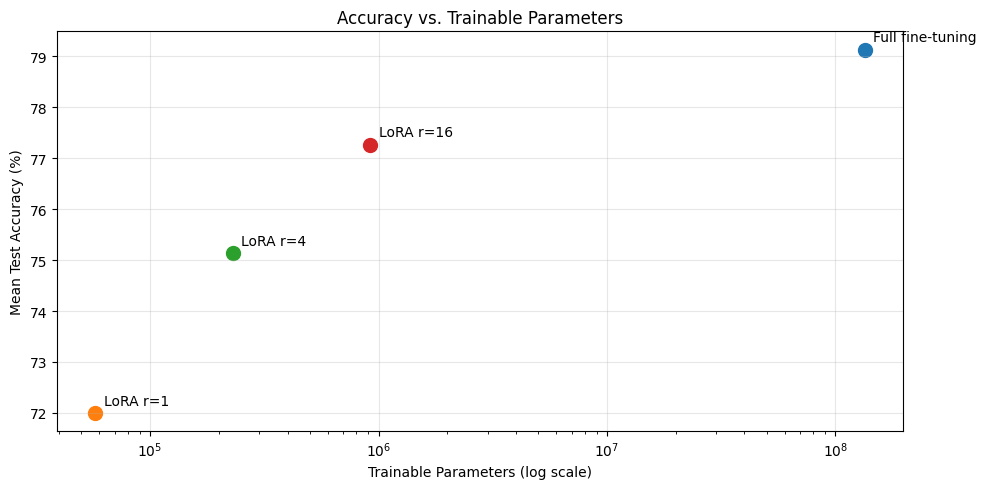

Figure saved to: C:\Users\dancm\OneDrive\Documentos\humber-aigc-postgraduate\aigc-5500-advanced-deep-learning\labs\lab-06\output\figures\accuracy_vs_parameters.png


In [35]:
# Prepare accuracy and parameter-count measurements
plot_data = rank_summary.copy()

# Create the accuracy versus trainable parameters figure
fig, ax = plt.subplots(figsize = (10, 5))

for _, row in plot_data.iterrows():
    ax.scatter(row['trainable'], row['Mean accuracy (%)'], s = 100, label=row['Method'])
    ax.annotate(row['Method'],(row['trainable'], row['Mean accuracy (%)'],), xytext = (6, 6), textcoords = 'offset points',)

# Use logarithmic scaling to accommodate large parameter differences
ax.set_xscale('log')

# Configure the plot
ax.set_title('Accuracy vs. Trainable Parameters')
ax.set_xlabel('Trainable Parameters (log scale)')
ax.set_ylabel('Mean Test Accuracy (%)')
ax.grid(True, alpha = 0.3)

plt.tight_layout()

# Save the figure for the repository README
figure_path = FIGURES_DIR / 'accuracy_vs_parameters.png'
fig.savefig(figure_path, dpi = 300, bbox_inches = 'tight')

plt.show()

print(f'Figure saved to: {figure_path}')